# **Session 9 - OOP Part 3 | Inheritance & Polymorphism | Static**

[Watch Here](https://www.youtube.com/live/bEWwM4hXZg8?si=pL6siFudrowZNnsn)

# **Class Relationships**

- ## Aggregation
- ## Inheritance

## **Aggregation (Has-A relationship)**

Aggregation is a type of association where one class contains another class as a part, but both can exist independently.

Represents a `Has-A relationship`

Objects are loosely coupled.

The contained object can exist without the container.

If the parent object is deleted, the child object still exists.

In [ ]:
# Example -> Customer has a Address

class Customer:
  def __init__(self,name,gender,address):
    self.name = name
    self.gender = gender
    # The Customer class has an Address object (aggregation)
    self.address = address

  def print_address(self):
    # Accessing Address object's attributes directly
    print(self.address.city,self.address.pin,self.address.state)


class Address:
  def __init__(self,city,pin,state):
    self.city = city
    self.pin = pin
    self.state = state

  def get_city(self):
    return self.city

# Create an Address object
add1 = Address('Banaras',221005,'UP')
# Create a Customer object, passing the Address object
cust = Customer('Nitish','Male',add1)

# Call a method that uses the aggregated Address object
cust.print_address()

Banaras 221005 UP


In [ ]:
# What about private attribute

class Customer:

  def __init__(self,name,gender,address):
    self.name = name
    self.gender = gender
    self.address = address

  def print_address(self):
    # Accessing private attribute through a public method of the Address class
    print(self.address.get_city(),self.address.pin,self.address.state)


class Address:
  def __init__(self,city,pin,state):
    # __city is a private attribute
    self.__city = city
    self.pin = pin
    self.state = state

  def get_city(self):
    # Public method to access the private __city attribute
    return self.__city

add1 = Address('Banaras',221005,'UP')
cust = Customer('Nitish','Male',add1)

cust.print_address()

Banaras 221005 UP


In [ ]:
# Method example

class Customer:

  def __init__(self,name,gender,address):
    self.name = name
    self.gender = gender
    self.address = address

  def print_address(self):
    # Accessing the mangled private attribute directly (not recommended for good practice)
    print(self.address._Address__city,self.address.pin,self.address.state)

  def edit_profile(self,new_name,new_city,new_pin,new_state):
    self.name = new_name
    # Calling a method of the aggregated Address object to modify its state
    self.address.edit_address(new_city,new_pin,new_state)

class Address:

  def __init__(self,city,pin,state):
      self.__city = city
      self.pin = pin
      self.state = state

  def get_city(self):
    return self.__city

  def edit_address(self,new_city,new_pin,new_state):
    # Method to update address details
    self.__city = new_city
    self.pin = new_pin
    self.state = new_state

# Create an Address object
add1 = Address('Banaras',221005,'UP')
# Create a Customer object
cust = Customer('nitish','male',add1)

cust.print_address()

# Edit customer profile and address using the edit_profile method
cust.edit_profile('ankit','Bumbai',111111,'Maharastra')
cust.print_address()

Banaras 221005 UP
Bumbai 111111 Maharastra


### **Aggregation class diagram**


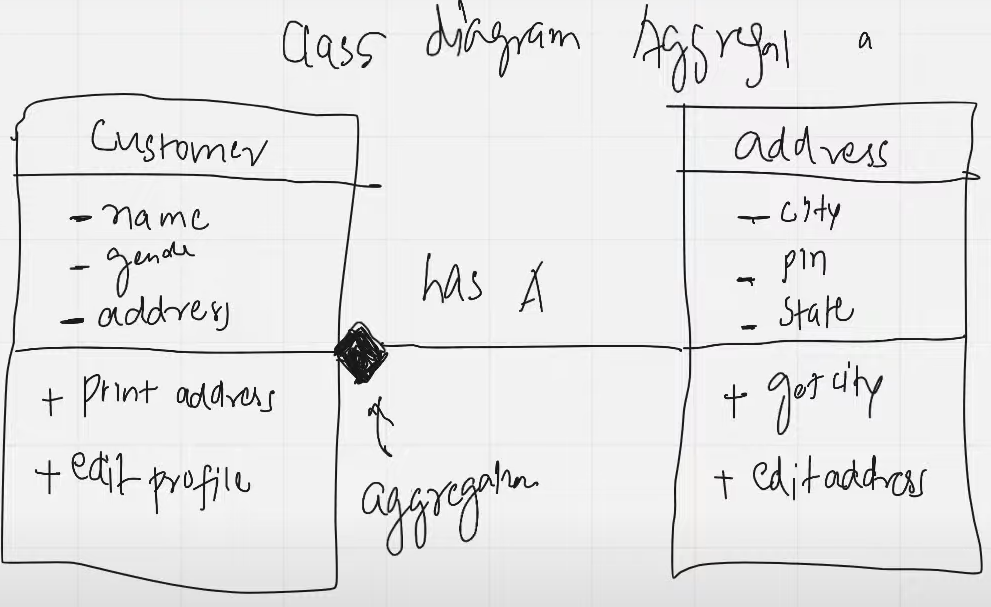

In [ ]:
# + denotes Public

# - denotes Private

## **Inheritance (IS-A relationship)**

- What is inheritance
- Example
- What gets inherited?

**What is inheritance**

Inheritance is an OOP concept where a child (derived) class acquires the properties and methods of a parent (base) class to achieve code reusability and hierarchical classification.

It represents an `IS-A relationship`

**Real-Life Example (Udemy Platform)**

In this Udemy example, both Student and Instructor require login and registration.

To avoid code duplication and follow the DRY principle, these common methods are placed in a User parent class.

Student and Instructor inherit from User and add their own specific behaviors.
This improves reusability, maintainability, and design clarity.

**Inheritance benefits**

Inheritance promotes code reusability, reduces redundancy, and helps in building a logical class hierarchy.

In [ ]:
# Example

# Parent class (Base class)
class User:

  def __init__(self):
    self.name = 'Himanshu'
    self.gender = 'male'

  def login(self):
    print('Login')

# Child class (Derived class) inheriting from User
class Student(User):

  # Student has its own specific method
  def enroll(self):
    print('Enroll into the course')

# Create an instance of the parent class
u = User()
# Create an instance of the child class
s = Student()

# Accessing inherited attribute from the User class
print(s.name)
# Calling inherited method from the User class
s.login()
# Calling method specific to the Student class
s.enroll()

Himanshu
Login
Enroll into the course


In [ ]:
# Class diagram

### **What gets inherited?**

- Constructor
- Non Private Attributes
- Non Private Methods

In [ ]:
# Constructor Example 1 -> Here child class has no constructor

class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.price = price
        self.brand = brand
        self.camera = camera

    def buy(self):
        print ("Buying a phone")

# SmartPhone inherits from Phone, but does not define its own __init__ method
class SmartPhone(Phone):
    pass

# When creating a SmartPhone object, Python automatically calls the __init__ of the parent (Phone) class.
s=SmartPhone(20000, "Apple", 13)

Inside phone constructor


In [ ]:
# Constructor Example 1.1
class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.price = price
        self.brand = brand
        self.camera = camera

    def buy(self):
        print ("Buying a phone")

class SmartPhone(Phone):
    pass

s=SmartPhone(20000, "Apple", 13)
# Calling the inherited method from the Phone class
s.buy()

Inside phone constructor
Buying a phone


In [ ]:
# Constructor Example 2 -> Child have its own constructor

class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera

# SmartPhone defines its own __init__ method
class SmartPhone(Phone):
    def __init__(self, os, ram):
        self.os = os
        self.ram = ram
        print ("Inside SmartPhone constructor")

# When creating a SmartPhone object, only its own __init__ is called. The parent's __init__ is not automatically called.
s=SmartPhone("Android", 2)

Inside SmartPhone constructor


In [ ]:
# Constructor Example 2.1
class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera

class SmartPhone(Phone):
    def __init__(self, os, ram):
        self.os = os
        self.ram = ram
        print ("Inside SmartPhone constructor")

s=SmartPhone("Android", 2)
# This will raise an AttributeError because the SmartPhone's __init__ did not call the Phone's __init__,
# so 'brand' was not initialized in the SmartPhone object.
s.brand()

Inside SmartPhone constructor


AttributeError: 'SmartPhone' object has no attribute 'brand'

In [ ]:
# Constructor Example 3 -> Child can't access private members of the class

class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera


    def show(self):
        print (self.price)

class SmartPhone(Phone):
    def check(self):
        print(self.__price)

s=SmartPhone(20000, "Apple", 13)
s.show()

Inside phone constructor


AttributeError: 'SmartPhone' object has no attribute 'price'

In [ ]:
# Constructor Example 3.1
class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera

    #getter
    def show(self):
        print (self.__price)

class SmartPhone(Phone):
    def check(self):
        print(self.__price)

s=SmartPhone(20000, "Apple", 13)
print(s.brand)
s.check()

Inside phone constructor
Apple


AttributeError: 'SmartPhone' object has no attribute '_SmartPhone__price'

In [ ]:
# Constructor Example 4 -> Child can access private members of the class using getter
class Parent:

    def __init__(self,num):
        self.__num=num

    def get_num(self):
        return self.__num

class Child(Parent):

    def show(self):
        print("This is in child class")

son=Child(100)
print(son.get_num())
son.show()

100
This is in child class


In [ ]:
# Constructor Example 5
class Parent:

    def __init__(self,num):
        self.__num=num

    def get_num(self):
        return self.__num

class Child(Parent):

    def __init__(self,val,num):
        self.__val=val

    def get_val(self):
        return self.__val

son=Child(100,10)
print("Parent: Num:",son.get_num())
print("Child: Val:",son.get_val())

AttributeError: 'Child' object has no attribute '_Parent__num'

In [ ]:
# Constructor Example 6 -> Here self.var1 and var1 both are different
class A:
    def __init__(self):
        self.var1=100

    def display1(self,var1):
        print("class A :", self.var1)
class B(A):

    def display2(self,var1):
        print("class B :", self.var1)

obj=B()
obj.display1(200)

class A : 100


In [ ]:
# Constructor Example 6.1
class A:
    def __init__(self):
        self.var1=100

    def display1(self,var1):
      self.var1 = var1
      print("class A :", self.var1)
class B(A):

    def display2(self,var1):
        print("class B :", self.var1)

obj=B()
obj.display1(200)

class A : 200


In [ ]:
# Method Overriding
class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera

    def buy(self):
        print ("Buying a phone")

class SmartPhone(Phone):
    def buy(self):
        print ("Buying a smartphone")

s=SmartPhone(20000, "Apple", 13)

s.buy()

Inside phone constructor
Buying a smartphone


### **Super Keyword**

super is used to access parent class methods, variables, or constructor from a child class.

It helps in code reuse and avoids duplication.

In [ ]:
# Super
class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera

    def buy(self):
        print ("Buying a phone")

class SmartPhone(Phone):
    def buy(self):
        print ("Buying a smartphone")
        # syntax to call parent ka buy method
        super().buy()

s=SmartPhone(20000, "Apple", 13)

s.buy()

Inside phone constructor
Buying a smartphone
Buying a phone


In [ ]:
# Using super outside the class -> No, bcos super is use inside the child class
class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera

    def buy(self):
        print ("Buying a phone")

class SmartPhone(Phone):
    def buy(self):
        print ("Buying a smartphone")
        # syntax to call parent ka buy method
        super().buy()

s=SmartPhone(20000, "Apple", 13)

super().buy()

Inside phone constructor


RuntimeError: super(): no arguments

In [ ]:
# Can super access parent ka data? No, bcos you cannot access attributes using super, you only access methods using super
class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera

    def buy(self):
        print ("Buying a phone")

class SmartPhone(Phone):
    def buy(self):
        print ("Buying a smartphone")
        # syntax to call parent ka buy method
        print(super().brand)

s=SmartPhone(20000, "Apple", 13)

s.buy()

Inside phone constructor
Buying a smartphone


AttributeError: 'super' object has no attribute 'brand'

In [ ]:
# super -> constuctor
class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera

class SmartPhone(Phone):
    def __init__(self, price, brand, camera, os, ram):
        print('Inside smartphone constructor')
        super().__init__(price, brand, camera)
        self.os = os
        self.ram = ram
        print ("Inside smartphone constructor")

s=SmartPhone(20000, "Samsung", 12, "Android", 2)

print(s.os)
print(s.brand)

Inside smartphone constructor
Inside phone constructor
Inside smartphone constructor
Android
Samsung


### **Inheritance in Summary**

- A class can inherit from another class.

- Inheritance improves code reuse

- Constructor, attributes, methods get inherited to the child class

- The parent has no access to the child class

- Private properties of parent are not accessible directly in child class

- Child class can override the attributes or methods. This is called method overriding

- super() is an inbuilt function which is used to invoke the parent class methods and constructor

In [ ]:
# Practice Question 1
class Parent:

    def __init__(self,num):
      self.__num=num

    def get_num(self):
      return self.__num

class Child(Parent):

    def __init__(self,num,val):
      super().__init__(num)
      self.__val=val

    def get_val(self):
      return self.__val

son=Child(100,200)
print(son.get_num())
print(son.get_val())

100
200


In [ ]:
# # Practice Question 2
class Parent:
    def __init__(self):
        self.num=100

class Child(Parent):

    def __init__(self):
        super().__init__()
        self.var=200

    def show(self):
        print(self.num)
        print(self.var)

son=Child()
son.show()

100
200


In [ ]:
# # Practice Question 3
class Parent:
    def __init__(self):
        self.__num=100

    def show(self):
        print("Parent:",self.__num)

class Child(Parent):
    def __init__(self):
        super().__init__()
        self.__var=10

    def show(self):
        print("Child:",self.__var)

obj=Child()
obj.show()

Child: 10


In [ ]:
# Practice Question 4
class Parent:
    def __init__(self):
        self.__num=100

    def show(self):
        print("Parent:",self.__num)

class Child(Parent):
    def __init__(self):
        super().__init__()
        self.__var=10

    def show(self):
        print("Child:",self.__var)

obj=Child()
obj.show()

Child: 10


### **Types of Inheritance**

- Single Inheritance
- Multilevel Inheritance
- Hierarchical Inheritance
- Multiple Inheritance(Diamond Problem)
- Hybrid Inheritance

In [ ]:
# Single Inheritance
class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera

    def buy(self):
        print ("Buying a phone")

class SmartPhone(Phone):
    pass

SmartPhone(1000,"Apple","13px").buy()

Inside phone constructor
Buying a phone


In [ ]:
# Multilevel Inheritance

class Product:
    def review(self):
        print ("Product customer review")

class Phone(Product):
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera

    def buy(self):
        print ("Buying a phone")

class SmartPhone(Phone):
    pass

s=SmartPhone(20000, "Apple", 12)

s.buy()
s.review()

Inside phone constructor
Buying a phone
Product customer review


In [ ]:
# Hierarchical Inheritance
class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera

    def buy(self):
        print ("Buying a phone")

class SmartPhone(Phone):
    pass

class FeaturePhone(Phone):
    pass

SmartPhone(1000,"Apple","13px").buy()
FeaturePhone(10,"Lava","1px").buy()

Inside phone constructor
Buying a phone
Inside phone constructor
Buying a phone


In [ ]:
# Multiple Inheritance
class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera

    def buy(self):
        print ("Buying a phone")

class Product:
    def review(self):
        print ("Customer review")

class SmartPhone(Phone, Product):
    pass

s=SmartPhone(20000, "Apple", 12)

s.buy()
s.review()


Inside phone constructor
Buying a phone
Customer review


In [ ]:
# The diamond problem -> https://stackoverflow.com/questions/56361048/what-is-the-diamond-problem-in-python-and-why-its-not-appear-in-python2
class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera

    def buy(self):
        print ("Buying a phone")

class Product:
    def buy(self):
        print ("Product buy method")

# Method Resolution Order (MRO)
class SmartPhone(Phone,Product):
    pass

s=SmartPhone(20000, "Apple", 12)

s.buy()

Inside phone constructor
Buying a phone


In [ ]:
# The diamond problem -> https://stackoverflow.com/questions/56361048/what-is-the-diamond-problem-in-python-and-why-its-not-appear-in-python2
class Phone:
    def __init__(self, price, brand, camera):
        print ("Inside phone constructor")
        self.__price = price
        self.brand = brand
        self.camera = camera

    def buy(self):
        print ("Buying a phone")

class Product:
    def buy(self):
        print ("Product buy method")

# Method Resolution Order (MRO)
class SmartPhone(Product,Phone):
    pass

s=SmartPhone(20000, "Apple", 12)

s.buy()

Inside phone constructor
Product buy method


In [ ]:
# Practice Question 1
class A:

    def m1(self):
        return 20

class B(A):

    def m1(self):
        return 30

    def m2(self):
        return 40

class C(B):

    def m2(self):
        return 20
obj1 = A()
obj2 = B()
obj3 = C()
print(obj1.m1() + obj3.m1() + obj3.m2())

70


In [ ]:
# Practice Question 2
class A:

    def m1(self):
        return 20

class B(A):

    def m1(self):
        val = super().m1() + 30
        return val

class C(B):

    def m1(self):
        val = self.m1() + 20
        return val
obj = C()
print(obj.m1())

RecursionError: maximum recursion depth exceeded

## **Polymorphism**

Polymorphism allows the same method or operator to behave differently.

- **Method Overriding** - Method overriding occurs when a child class redefines a parent method.

- **Method Overloading** - When a child class provides its own implementation of a parent class method with the same name and parameters. Python does not support traditional method overloading but achieves it using default or variable arguments.

- **Operator Overloading** - Operator overloading allows operators to work with user-defined objects using magic methods.

In [ ]:
# Method Overloading
class Shape:

  def area(self,radius):
    return 3.14*radius*radius

  def area(self,l,b):
    return l*b

s = Shape()

s.area(2)

TypeError: Shape.area() missing 1 required positional argument: 'b'

In [ ]:
# Method Overloading -> Benifit is that the code is more clean
class Shape:

  def area(self,a,b=0):
    if b == 0:
      return 3.14*a*a
    else:
      return a*b

s = Shape()

print(s.area(2))
print(s.area(3,4))

12.56
12


In [ ]:
# Operator Overloading
'hello' + 'world'

'helloworld'

In [ ]:
4 + 5

9

In [ ]:
[1,2,3] + [4,5]

[1, 2, 3, 4, 5]

## **Abstraction**

[Watch Here](https://youtu.be/O-NrQvtorp0?si=lFr4TMwJxPlbnTEJ)

Abstraction hides implementation details and exposes only essential functionality.

In Python, it is achieved using abstract classes and abstract methods via the abc module.

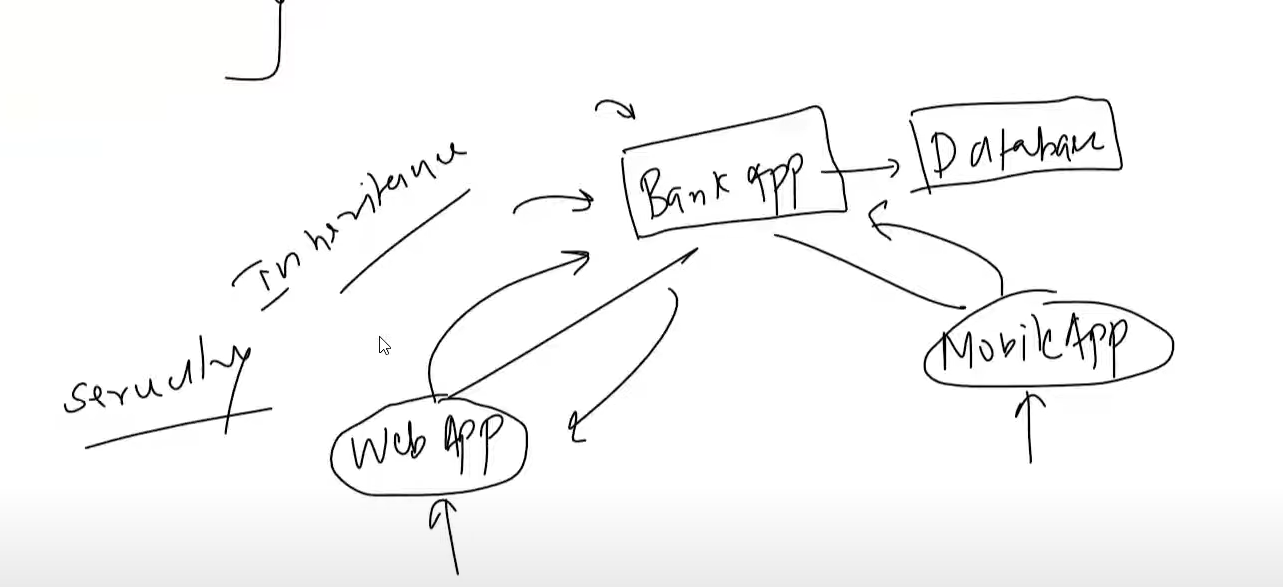


**Abstract Class** -
An abstract class is a blueprint that cannot be instantiated and is used to enforce method implementation in derived classes.

- In Python, it is created using the abc module.

**Abstract Method** -
An abstract method is a method without implementation defined in an abstract class.

- It ensures that all child classes implement that method.

In [ ]:
from abc import ABC,abstractmethod
class BankApp(ABC):

  def database(self):
    print('connected to database')

  @abstractmethod
  def security(self):
    pass

  @abstractmethod
  def display(self):
    pass

In [ ]:
class MobileApp(BankApp):

  def mobile_login(self):
    print('login into mobile')

  def security(self):
    print('mobile security')

  def display(self):
    print('display')

In [ ]:
mob = MobileApp()

In [ ]:
mob.security()

mobile security


In [ ]:
obj = BankApp()

TypeError: Can't instantiate abstract class BankApp without an implementation for abstract methods 'display', 'security'